Matias Lanas 22.466.806-6

Problema 1

In [34]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(seed = 324007)

In [35]:
tiempo = np.linspace(0, 10, 500)
#Definimos el tiempo desde 0 años hasta 10 años con 500 puntos equidistantes.

flujo_normalizado = np.ones(500)
ruido_gaussiano = np.random.normal(loc=0, scale=0.002, size=500)
#Definimos el flujo normalizado como mediciones de unos y agregamos ruido gaussiano con media 0 y desviación estándar 0.002.

flujo_real = flujo_normalizado + ruido_gaussiano
#Definimos el flujo real como la suma del flujo normalizado y el ruido gaussiano.

mascara_intervalo1 = (tiempo >= 4.5) & (tiempo <= 5.0)
mascara_intervalo2 = (tiempo >= 7.0) & (tiempo <= 7.4)
#Intervalos de tiempo mostrados en la tarea

flujo_real[mascara_intervalo1] -= 0.02
flujo_real[mascara_intervalo2] -= 0.015
#Disminuciones del flujo real en los intervalos de tiempo especificados.

In [36]:
def Graficar_curva_de_luz(t, flujo):
    '''
    En esta función se graficará la curva de luz del flujo normalizado y del flujo real en función del tiempo, además de cumplir con todas las especificaciones de la tarea.
    ------------------
    Párametros: 
    t = tiempo (numpy array)
    flujo = flujo real (numpy array)
    ------------------
    Retorna: Un gráfico de la curva de luz que contiene:
    1.- Puntos normales en la curva de luz (azul)
    2.- Puntos debajo del umbral de detección (rojo)
    3.- Línea horizontal del flujo promedio (negro)
    4.- Línea horizontal del umbral de detección (naranja)
    
    '''

    #Calculo del promedio y del umbral de deteccion (3-sigma)
    F_promedio = np.mean(flujo)
    sigma = np.std(flujo)
    umbral_deteccion = F_promedio - 3*sigma

    #Condicion dada para detectar puntos debajo del umbral (Flujo < Flujo promedio - 3*sigma)
    condicion = flujo < umbral_deteccion

    #Creamos la figura y los ejes
    fig, ax = plt.subplots(figsize=(16, 10))

    #1.- Puntos normales en la curva de luz
    ax.scatter(t[~condicion], flujo[~condicion], color='blue', alpha=0.6, label='Puntos normales')

    #2.- Puntos debajo del umbral de detección
    ax.scatter(t[condicion], flujo[condicion], color='red',marker='v',s=50, alpha=0.6, label='Puntos debajo del umbral de detección')

    #3.- Línea horizontal del flujo promedio
    ax.axhline(F_promedio, color='black', linestyle='--', label='Flujo promedio')

    #4.- Línea horizontal del umbral de detección
    ax.axhline(umbral_deteccion, color='orange', linestyle=':', label='Umbral de detección (3-sigma)')

    #5.- Lineas verticales para el inicio y el fin de los transitos simulados
    ax.axvline(4.5, color='green', linestyle='-',alpha=0.7, label='Tránsito 1 [4.5 - 5.0 años]')
    ax.axvline(5.0, color='green', linestyle='-',alpha=0.7)

    ax.axvline(7.0, color='purple', linestyle='-',alpha=0.7, label='Tránsito 2 [7.0 - 7.4 años]')
    ax.axvline(7.4, color='purple', linestyle='-',alpha=0.7)

    #6.- Etiquetas de los ejes y leyenda con tamaño de fuente 14
    ax.set_xlabel('Tiempo (años)', fontsize=14)
    ax.set_ylabel('Flujo normalizado', fontsize=14)
    ax.set_title('Curva de luz con transitos simulados', fontsize=16)
    ax.legend(fontsize=14, loc='lower left')
    ax.grid(True, alpha=0.3)

    plt.show()



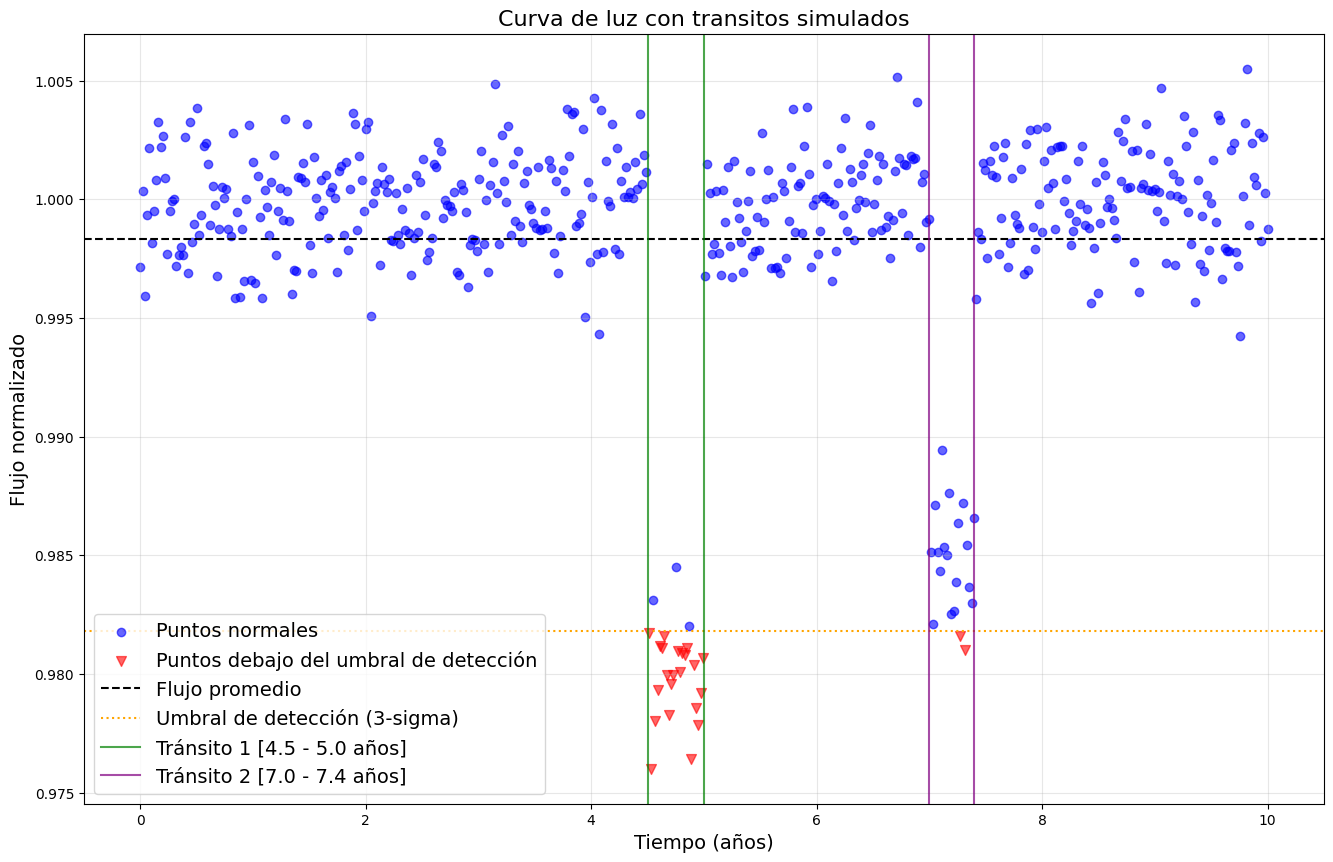

In [37]:
Graficar_curva_de_luz(tiempo, flujo_real)

Problema 2

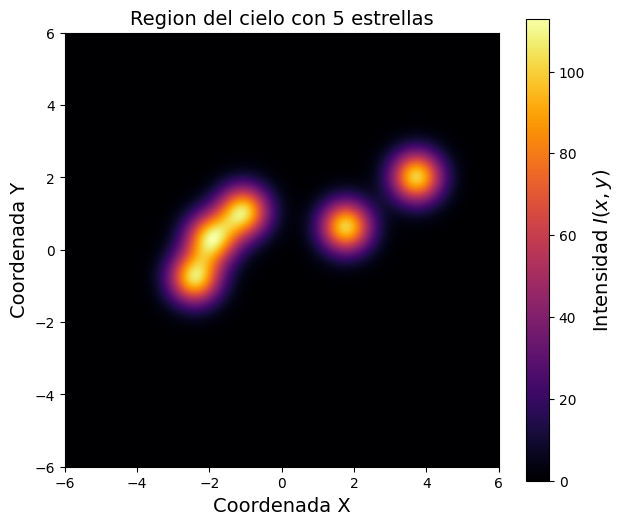

In [38]:
#Enunciado a) del problema
#Primero definimos nuestras variables y las 5 estrellas que se van a medir
Nestrellas = 5
I0 = 100.0
sigma = 0.5
x0 = rng.uniform(-5, 5, Nestrellas)
y0 = rng.uniform(-5, 5, Nestrellas)

#Definimos la grilla espacial (x,y)
x = np.linspace(6, -6, 200)
y = np.linspace(6, -6, 200)
X, Y  = np.meshgrid(x, y)

#Sumamos la intensidad de cada una de las 5 estrellas
imagen = np.zeros_like(X)
for i in range(Nestrellas):
    imagen += I0 * np.exp(-((X - x0[i])**2 + (Y - y0[i])**2) / (2*sigma**2))

#Graficamos la imagen definida
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(imagen, extent=[-6, 6, -6, 6], origin='lower', cmap='inferno') #extent = [-6, 6, -6, 6] sirve para que los ejes corresponda a valores fisicos de x e y
cbar = fig.colorbar(im, ax=ax)
cbar.set_label('Intensidad $I(x, y)$', fontsize=14)

ax.set_xlabel('Coordenada X', fontsize=14)
ax.set_ylabel('Coordenada Y', fontsize=14)
ax.set_title('Region del cielo con 5 estrellas', fontsize=14)
plt.show()

In [39]:
#Enunciado b) del probelema
#Creamos nuestra funcion
def calcular_distancias(x0, y0):
    '''
    Esta funcion calcula las distancias euclidianas entre los centros de cada estrella
    -------------
    Parámetros:
    x0 = Distancia inicial en x
    y0 = Distancia inicial en y
    -------------
    Retorna: Las distancias euclidianas entre cada par de estrellas

    '''

    N = len(x0)
    #Matriz cuadrada para guardar las distancias
    distancias = np.zeros((N, N))

    for i in range(N):
        for j in range(N):
            distancias[i, j] = np.sqrt((x0[i] - x0[j])**2 + (y0[i] - y0[j])**2)
            #Formula de las distancias euclidianas: sqrt((x2 - x1)^2 + (y2 - y1)^2)

    return distancias

matriz_distancias = calcular_distancias(x0, y0)
print('Matriz de las distancias entre estrellas:\n', np.round(matriz_distancias, 2))

Matriz de las distancias entre estrellas:
 [[0.   6.78 4.91 5.95 2.4 ]
 [6.78 0.   2.29 1.19 4.44]
 [4.91 2.29 0.   1.16 2.88]
 [5.95 1.19 1.16 0.   3.74]
 [2.4  4.44 2.88 3.74 0.  ]]


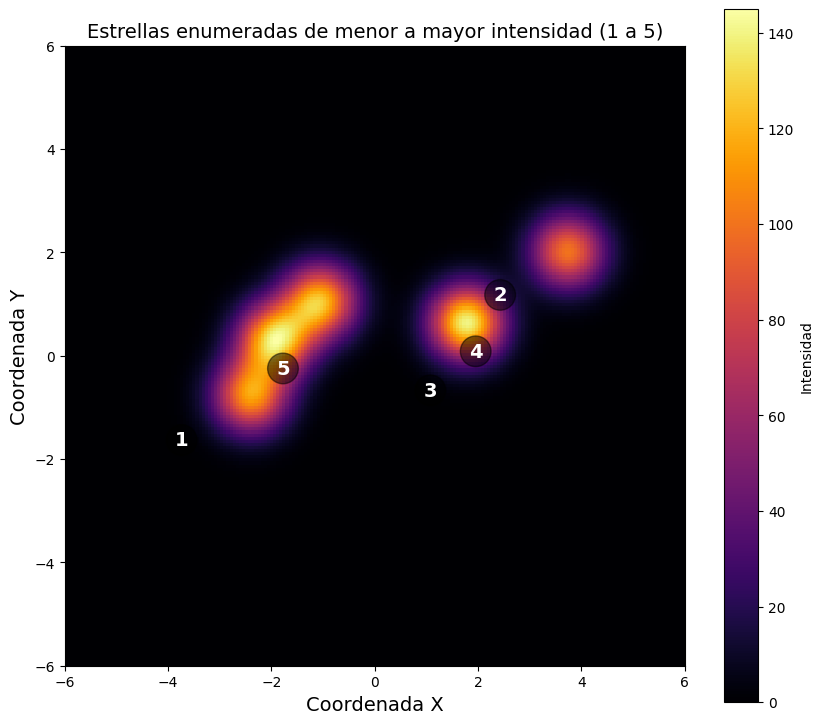

In [40]:
#Enunciado c) del problema
#Variamos un poco las intensidades ya que todas las estrellas poseen I0 = 100
Intensidades = I0 * (1 + 0.1 * np.arange(Nestrellas))

#Volvemos a generar nuestra imagen con estas intensidades
imagen_c = np.zeros_like(X)
for i in range(Nestrellas):
    imagen_c += Intensidades[i] * np.exp(-((X - x0[i])**2 + (Y - y0[i])**2) / (2*sigma**2))

#Ordenamos de menor a mayor intensidad
indices_ordenados = np.argsort(Intensidades)

fig, ax = plt.subplots(figsize=(10,9))
im = ax.imshow(imagen_c, extent=[-6,6,-6,6], origin='lower', cmap='inferno')
fig.colorbar(im, ax=ax, label='Intensidad')

#Enumeramos las estrellas del 1 al 5 según la intensidad de cada una
for numero, idx in enumerate(indices_ordenados, start=1):
    ax.text(x0[idx], y0[idx] + 0.4, str(numero), color='white', fontsize=14, fontweight='bold', ha='center', va='center', bbox=dict(boxstyle='circle', facecolor='black', alpha=0.5))

ax.set_xlabel('Coordenada X', fontsize=14)
ax.set_ylabel('Coordenada Y', fontsize=14)
ax.set_title('Estrellas enumeradas de menor a mayor intensidad (1 a 5)', fontsize=14)
plt.show()

<>:17: SyntaxWarning: invalid escape sequence '\s'
<>:17: SyntaxWarning: invalid escape sequence '\s'
C:\Users\matia\AppData\Local\Temp\ipykernel_25924\677461872.py:17: SyntaxWarning: invalid escape sequence '\s'
  axes[k].set_title(f'Gráfico variando la variable sigma $\sigma = {sig}$')


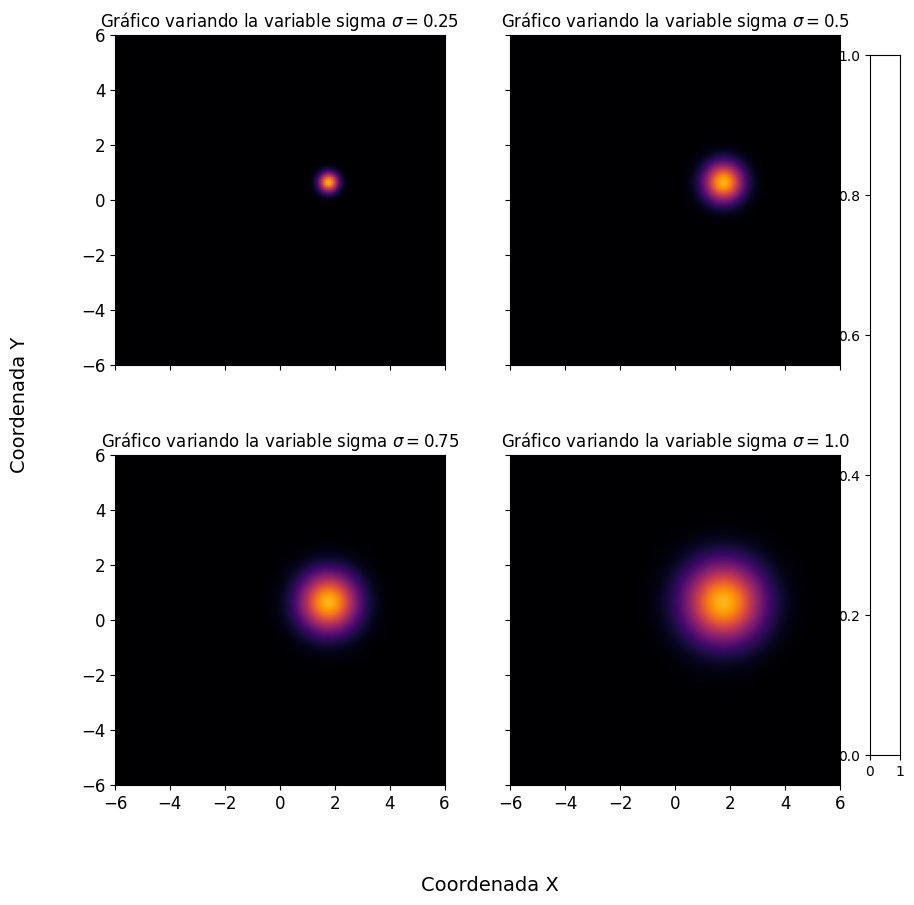

In [41]:
#Enunciado d) del problema
#Primero variamos nuestra variable sigma con una lista
sigmas = [0.25, 0.5, 0.75, 1.0]

fig, axes = plt.subplots(2, 2, figsize=(10, 10), sharex=True, sharey=True) #sharex y sharey para compartir ejes
axes = axes.flatten()

#Calculamos el valor máximo global para compartir la misma escala de color
vmax_global = 120.0

for k, sig in enumerate(sigmas):
    img_sig = np.zeros_like(X)
    for i in range(Nestrellas):
        img_sig = I0 * np.exp(-((X - x0[i])**2 + (Y - y0[i])**2) / (2*sig**2))

    im = axes[k].imshow(img_sig, extent=[-6,6,-6,6], origin='lower', cmap='inferno', vmin=0, vmax=vmax_global)
    axes[k].set_title(f'Gráfico variando la variable sigma $\sigma = {sig}$')

#Agregamos una única barra de color para todos los subplots
fig.subplots_adjust(right=0.85)
cbar_ax = fig.add_axes([0.88, 0.15, 0.03, 0.7])

for ax in axes:
    ax.tick_params(labelsize=12)

fig.supxlabel('Coordenada X', fontsize=14)
fig.supylabel('Coordenada Y', fontsize=14)
plt.show()

Como podemos ver, a medida que  $\sigma$ aumenta, las estrellas se vuelven espacialmente más anchas y difusas.